In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("cybersecurity_intrusion_data.csv")
df

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0
...,...,...,...,...,...,...,...,...,...,...,...
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1
9533,SID_09534,380,TCP,3,182.848475,NaN,0.408485,0,Chrome,0,0
9534,SID_09535,664,TCP,5,35.170248,AES,0.359200,1,Firefox,0,0
9535,SID_09536,406,TCP,4,86.664703,AES,0.537417,1,Chrome,1,0


In [3]:
print(df.head())
print(df.tail())
print(df.shape)

  session_id  network_packet_size protocol_type  login_attempts  \
0  SID_00001                  599           TCP               4   
1  SID_00002                  472           TCP               3   
2  SID_00003                  629           TCP               3   
3  SID_00004                  804           UDP               4   
4  SID_00005                  453           TCP               5   

   session_duration encryption_used  ip_reputation_score  failed_logins  \
0        492.983263             DES             0.606818              1   
1       1557.996461             DES             0.301569              0   
2         75.044262             DES             0.739164              2   
3        601.248835             DES             0.123267              0   
4        532.540888             AES             0.054874              1   

  browser_type  unusual_time_access  attack_detected  
0         Edge                    0                1  
1      Firefox                    0 

EDA

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   object 
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   object 
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   object 
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   object 
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 819.7+ KB


In [5]:
df.describe()

,network_packet_size,login_attempts,session_duration,ip_reputation_score,failed_logins,unusual_time_access,attack_detected
count,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000
mean,500.430639,4.032086,792.745312,0.331338,1.517773,0.149942,0.447101
std,198.379364,1.963012,786.560144,0.177175,1.033988,0.357034,0.497220
min,64.000000,1.000000,0.500000,0.002497,0.000000,0.000000,0.000000
25%,365.000000,3.000000,231.953006,0.191946,1.000000,0.000000,0.000000
50%,499.000000,4.000000,556.277457,0.314778,1.000000,0.000000,0.000000
75%,635.000000,5.000000,1105.380602,0.453388,2.000000,0.000000,1.000000
max,1285.000000,13.000000,7190.392213,0.924299,5.000000,1.000000,1.000000


In [6]:
df.isnull().sum()

session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64

In [7]:
print((df.isnull().sum() / len(df)) * 100)

session_id              0.000000
network_packet_size     0.000000
protocol_type           0.000000
login_attempts          0.000000
session_duration        0.000000
encryption_used        20.614449
ip_reputation_score     0.000000
failed_logins           0.000000
browser_type            0.000000
unusual_time_access     0.000000
attack_detected         0.000000
dtype: float64


In [8]:
#duplicates

df.duplicated().sum()

np.int64(0)

In [9]:
#target variable -> attack_dtected

df["attack_detected"].value_counts()

attack_detected
0    5273
1    4264
Name: count, dtype: int64

Text(0, 0.5, 'Number of attacks')

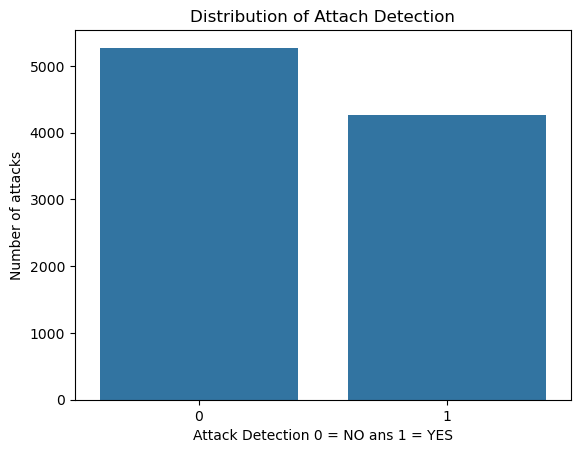

In [10]:
#graph of target varialbe to show how many 0s and 1s are there

import seaborn as sns

sns.countplot(data= df, x = "attack_detected")
plt.title("Distribution of Attach Detection")
plt.xlabel("Attack Detection 0 = NO ans 1 = YES")
plt.ylabel("Number of attacks")

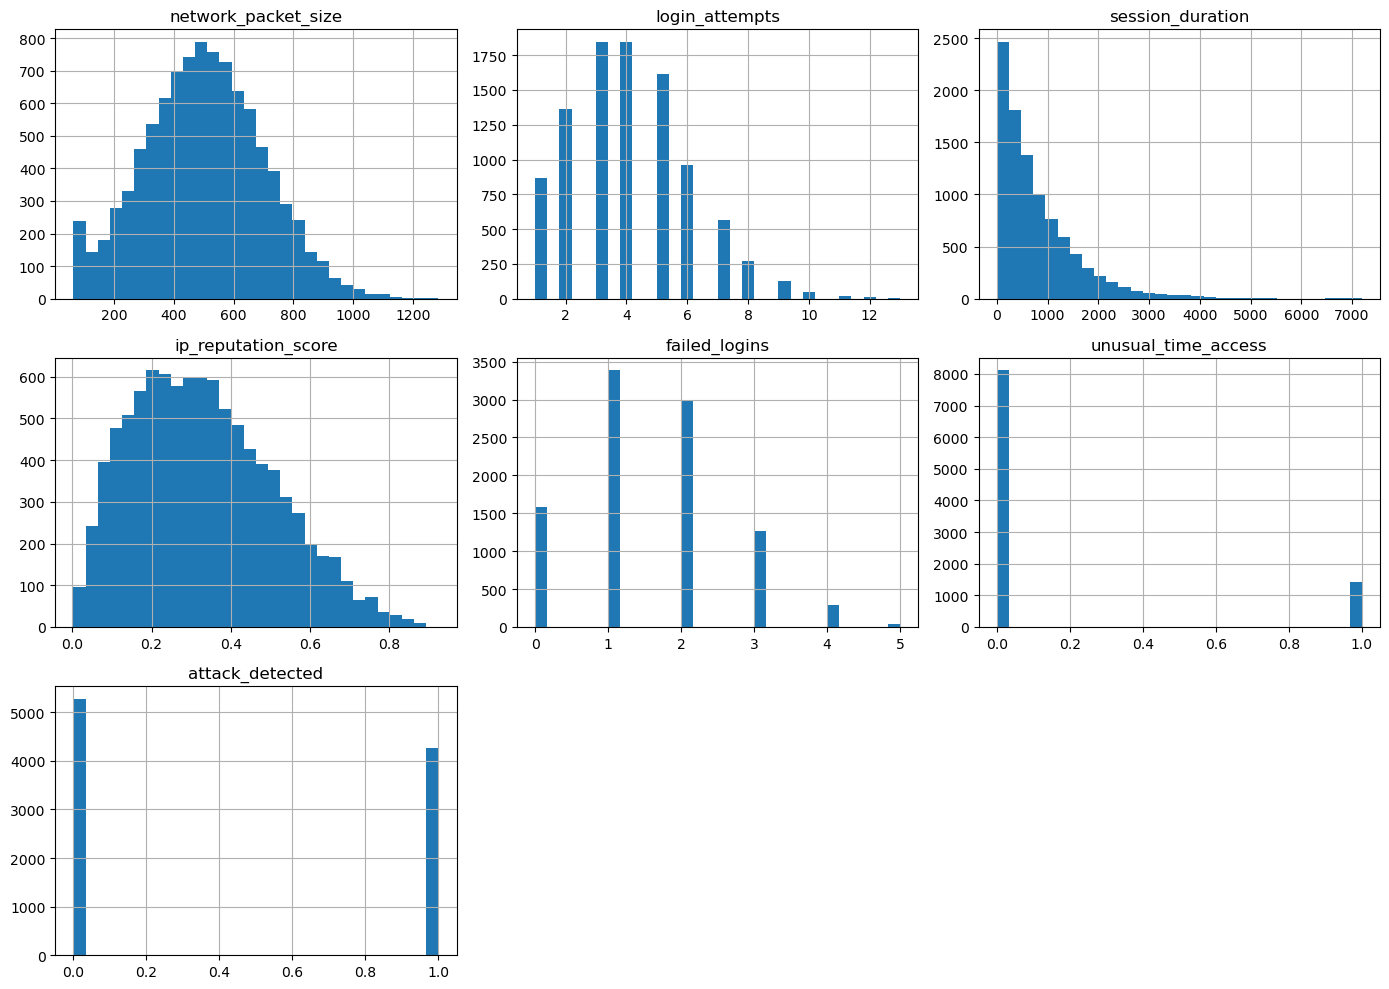

In [11]:
#numerical columns 

numerical_cols = [
    "network_packet_size",
    "login_attempts",
    "session_duration",
    "ip_reputation_score",
    "failed_logins",
    "unusual_time_access",
    "attack_detected"
]

df[numerical_cols].hist(
    figsize = (14, 10),
    bins = 30
)

plt.tight_layout()
plt.show()

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   object 
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   object 
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   object 
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   object 
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 819.7+ KB


In [13]:
print(df["session_id"].value_counts())
print(df["protocol_type"].value_counts())
print(df["encryption_used"].value_counts(dropna=False))
print(df["browser_type"].value_counts())

session_id
SID_00001    1
SID_06354    1
SID_06356    1
SID_06357    1
SID_06358    1
            ..
SID_03180    1
SID_03181    1
SID_03182    1
SID_03183    1
SID_09537    1
Name: count, Length: 9537, dtype: int64
protocol_type
TCP     6624
UDP     2406
ICMP     507
Name: count, dtype: int64
encryption_used
AES    4706
DES    2865
NaN    1966
Name: count, dtype: int64
browser_type
Chrome     5137
Firefox    1944
Edge       1469
Unknown     502
Safari      485
Name: count, dtype: int64


<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

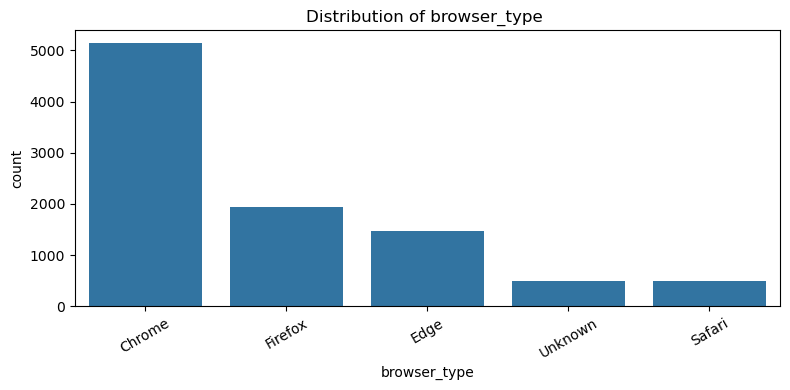

In [14]:
#visualization

categorical_cols = [
    "protocol_type",
    "encryption_used",
    "browser_type"
]

for col in categorical_cols:
    plt.figure(figsize = (8, 4))

sns.countplot(
    data = df,
    x = col,
    order=df[col].value_counts().index
)

plt.title(f"Distribution of {col} ")
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

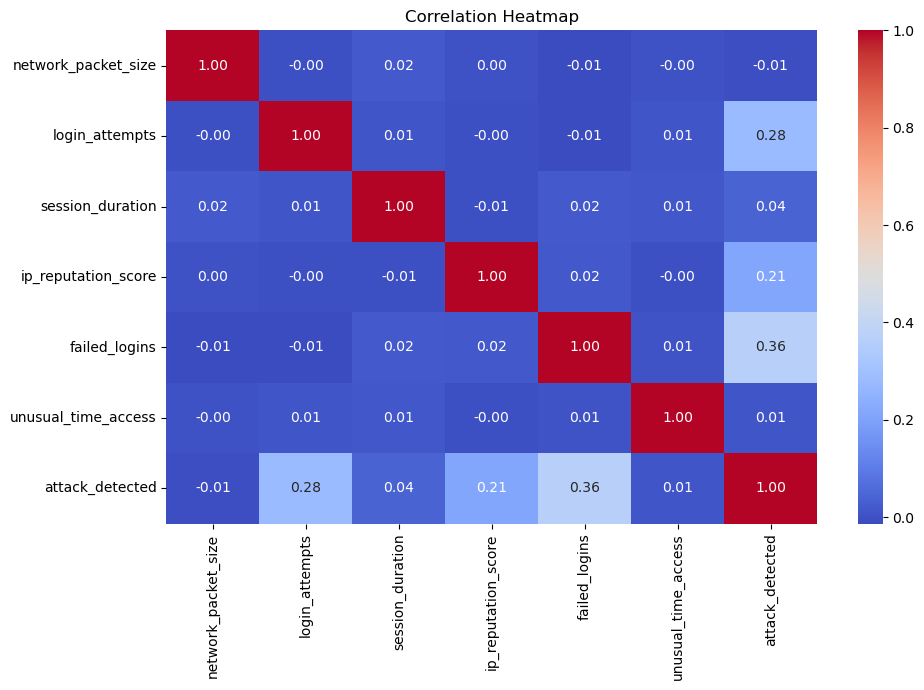

In [15]:
#correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

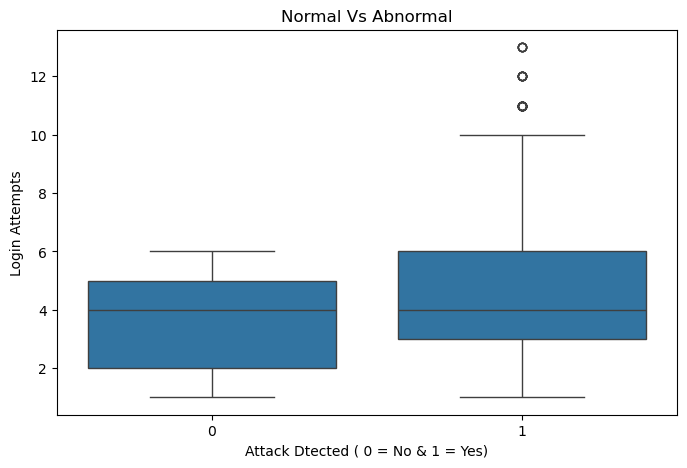

In [16]:
#outlier and disribution

plt.figure(figsize=(8, 5))

sns.boxplot(data = df, x = "attack_detected", y ="login_attempts")

plt.title("Normal Vs Abnormal")
plt.xlabel("Attack Dtected ( 0 = No & 1 = Yes)")
plt.ylabel("Login Attempts")

plt.show()

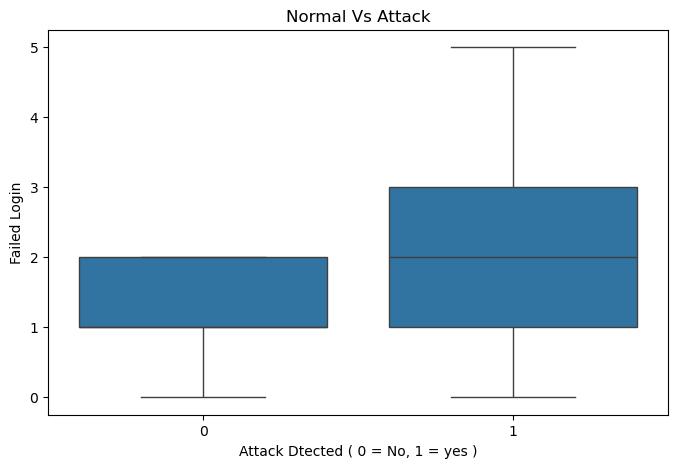

In [17]:
#login vs Attack

plt.figure(figsize = (8, 5))

sns.boxplot(data = df, x = "attack_detected", y = "failed_logins")

plt.title("Normal Vs Attack")
plt.xlabel("Attack Dtected ( 0 = No, 1 = yes )")
plt.ylabel("Failed Login")

plt.show()

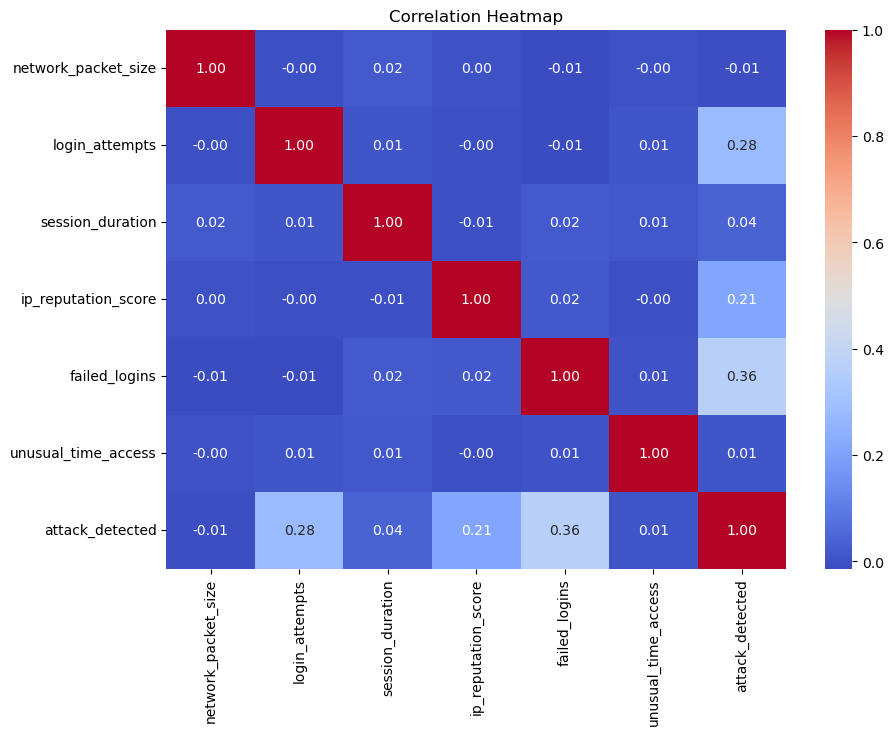

In [18]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap")

plt.show()

1.Boxplot:-
In the abnormal section, users usally login with high attempts.

2.Correlation Heatmap:-
failed_logins = 0.36 (big one)
login_attempts :- 0.28 (positive)
ip_reputation_score = 0.21 (may be weak)
session_duration = 0.04 (weakest)
unusual_time_aces = 0.01 (around 0)

In [19]:
#protocl type vs attack

pd.crosstab(
    df["protocol_type"],
    df["attack_detected"],
    normalize = "index"
) * 100

attack_detected,0,1
protocol_type,,
ICMP,58.777120,41.222880
TCP,55.268720,44.731280
UDP,54.613466,45.386534


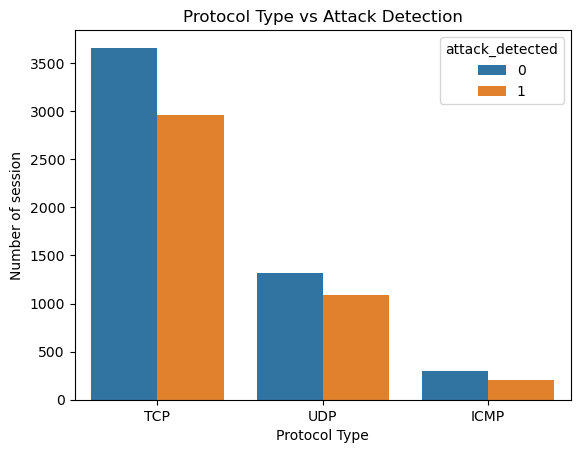

In [20]:
#graph:-

sns.countplot(
    data = df,
    x = "protocol_type",
    hue = "attack_detected"
)

plt.title("Protocol Type vs Attack Detection")
plt.xlabel("Protocol Type")
plt.ylabel("Number of session")
plt.show()

In [21]:
#type vs attack

pd.crosstab(
    df["browser_type"],
    df["attack_detected"],
    normalize = "index"
)*100

attack_detected,0,1
browser_type,,
Chrome,57.134514,42.865486
Edge,56.228727,43.771273
Firefox,56.327160,43.672840
Safari,58.144330,41.855670
Unknown,26.892430,73.107570


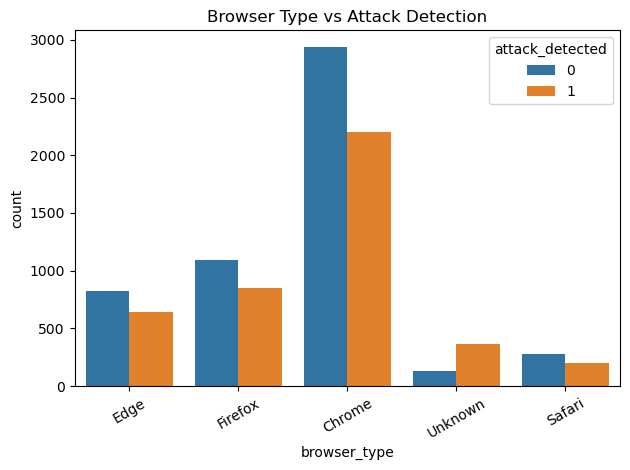

In [22]:
#graph:-

sns.countplot(
    data = df,
    x = "browser_type",
    hue = "attack_detected"
)

plt.title("Browser Type vs Attack Detection")
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

pd.crosstab(
    df["unusual_time_access"],
    df["attack_detected"],
    normalize="index"
)*100

## EDA Summary

1. The dataset contains 9,537 records and 11 columns.
2. The encryption_used column contains missing values.
3. No exact duplicate rows were found.
4. The target variable contains both normal and attack-detected sessions.
5. Failed logins and login attempts show positive correlations with attack_detected.
6. UDP has a slightly higher attack-detection percentage than TCP and ICMP.
7. The Unknown browser category has a higher attack-detection percentage
   than the other browser categories.
8. Unusual time access shows only a small difference in attack percentages.

### Conclusion
EDA identified potentially useful features for further investigation.
These observations will guide preprocessing and model development.

In [23]:
print("Browser Type Counts:")
print(df["browser_type"].value_counts(dropna=False))
print(df["encryption_used"].value_counts(dropna=False))

Browser Type Counts:
browser_type
Chrome     5137
Firefox    1944
Edge       1469
Unknown     502
Safari      485
Name: count, dtype: int64
encryption_used
AES    4706
DES    2865
NaN    1966
Name: count, dtype: int64


##Preprocessing

In [24]:
#filling missing values with unknown browser

df_clean = df.copy()

df_clean["encryption_used"] = df_clean["encryption_used"].fillna("Unknown")


In [25]:
df_clean["encryption_used"].value_counts(dropna=False)

encryption_used
AES        4706
DES        2865
Unknown    1966
Name: count, dtype: int64

In [26]:
#Recheck missing values

df_clean.isnull().sum()

session_id             0
network_packet_size    0
protocol_type          0
login_attempts         0
session_duration       0
encryption_used        0
ip_reputation_score    0
failed_logins          0
browser_type           0
unusual_time_access    0
attack_detected        0
dtype: int64

In [27]:
#session_id

df_clean = df_clean.drop(columns=["session_id"])

In [28]:
#categorical Encoding

df_encoded = pd.get_dummies(
    df_clean,
    columns = ["protocol_type", "encryption_used", "browser_type"],
    dtype=int
)

In [29]:
df_encoded.head()

,network_packet_size,login_attempts,session_duration,ip_reputation_score,failed_logins,unusual_time_access,attack_detected,protocol_type_ICMP,protocol_type_TCP,protocol_type_UDP,encryption_used_AES,encryption_used_DES,encryption_used_Unknown,browser_type_Chrome,browser_type_Edge,browser_type_Firefox,browser_type_Safari,browser_type_Unknown
0,599,4,492.983263,0.606818,1,0,1,0,1,0,0,1,0,0,1,0,0,0
1,472,3,1557.996461,0.301569,0,0,0,0,1,0,0,1,0,0,0,1,0,0
2,629,3,75.044262,0.739164,2,0,1,0,1,0,0,1,0,1,0,0,0,0
3,804,4,601.248835,0.123267,0,0,1,0,0,1,0,1,0,0,0,0,0,1
4,453,5,532.540888,0.054874,1,0,0,0,1,0,1,0,0,0,0,1,0,0


In [30]:
print("Original shape:", df.shape)
print("After preprocessing:", df_encoded.shape)

Original shape: (9537, 11)
After preprocessing: (9537, 18)


In [31]:
#seprating feature and target

X = df_encoded.drop(columns=["attack_detected"])

y = df_encoded["attack_detected"]

In [32]:
print("Features Shape:", X.shape)
print("Target shape:", y.shape)

Features Shape: (9537, 17)
Target shape: (9537,)


In [33]:
#Train test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y

)

In [34]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7629, 17)
X_test: (1908, 17)
y_train: (7629,)
y_test: (1908,)


In [35]:
#Target Distirubtion

print("Training target distribution:")
print(y_train.value_counts(normalize=True)*100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True)*100)

Training target distribution:
attack_detected
0    55.289029
1    44.710971
Name: proportion, dtype: float64

Testing target distribution:
attack_detected
0    55.293501
1    44.706499
Name: proportion, dtype: float64


In [36]:
#model

from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.4471,
    random_state=42
)

model.fit(X_train)

,n_estimators,100
,max_samples,'auto'
,contamination,0.4471
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [37]:
y_pred = model.predict(X_test)

In [38]:
y_pred

array([-1, -1, -1, ...,  1, -1,  1], shape=(1908,))

In [39]:
#change it to 0 and 1

y_pred = (y_pred == -1).astype(int)

In [40]:
y_pred

array([1, 1, 1, ..., 0, 1, 0], shape=(1908,))

In [41]:
#evaluation od model

from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix: ", classification_report(y_test, y_pred))
print("\nClassification_report:", classification_report(y_test, y_pred))

Confusion Matrix:                precision    recall  f1-score   support

           0       0.61      0.61      0.61      1055
           1       0.51      0.51      0.51       853

    accuracy                           0.56      1908
   macro avg       0.56      0.56      0.56      1908
weighted avg       0.56      0.56      0.56      1908


Classification_report:               precision    recall  f1-score   support

           0       0.61      0.61      0.61      1055
           1       0.51      0.51      0.51       853

    accuracy                           0.56      1908
   macro avg       0.56      0.56      0.56      1908
weighted avg       0.56      0.56      0.56      1908



In [42]:
## Random Rorest

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8825995807127882

Confusion Matrix:
[[1048    7]
 [ 217  636]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1055
           1       0.99      0.75      0.85       853

    accuracy                           0.88      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.88      0.88      1908



                    Feature  Importance
4             failed_logins    0.272362
3       ip_reputation_score    0.221303
1            login_attempts    0.218234
2          session_duration    0.105507
0       network_packet_size    0.098699
16     browser_type_Unknown    0.024390
5       unusual_time_access    0.009475
7         protocol_type_TCP    0.005793
8         protocol_type_UDP    0.005723
12      browser_type_Chrome    0.005642
14     browser_type_Firefox    0.005639
10      encryption_used_DES    0.005357
9       encryption_used_AES    0.005243
11  encryption_used_Unknown    0.005236
13        browser_type_Edge    0.004885
6        protocol_type_ICMP    0.003265
15      browser_type_Safari    0.003249


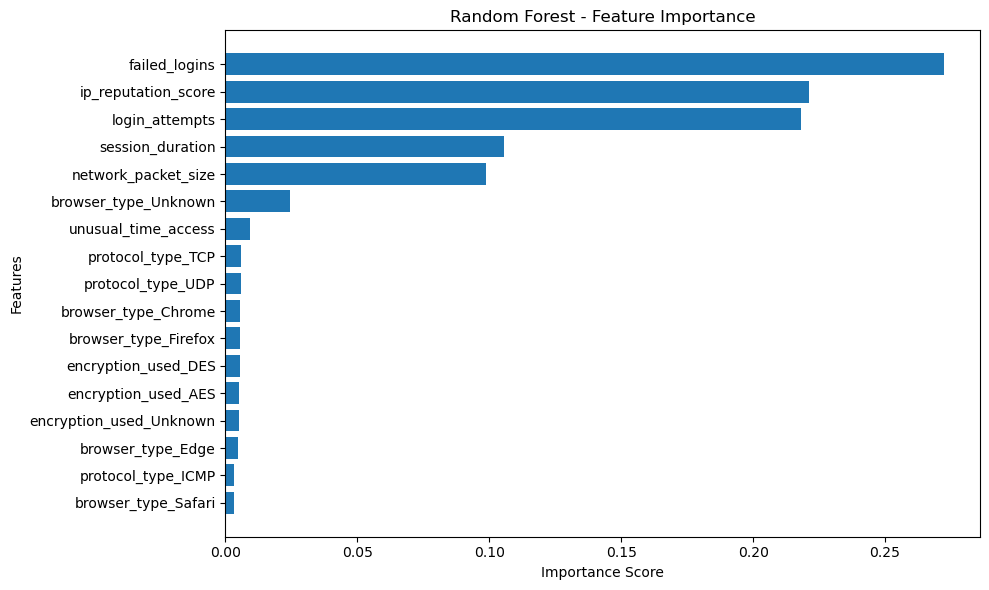

In [44]:
#graph

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [57]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb.fit(X_train, y_train)

y_pred_gb = model_gb.predict(X_test)

print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.8857442348008385

Confusion Matrix:
[[1054    1]
 [ 217  636]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      1055
           1       1.00      0.75      0.85       853

    accuracy                           0.89      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.89      0.88      1908



                    Feature  Importance
4             failed_logins    0.388768
1            login_attempts    0.314153
3       ip_reputation_score    0.238941
16     browser_type_Unknown    0.035700
2          session_duration    0.010542
0       network_packet_size    0.005546
5       unusual_time_access    0.004404
14     browser_type_Firefox    0.000912
9       encryption_used_AES    0.000502
12      browser_type_Chrome    0.000360
6        protocol_type_ICMP    0.000078
8         protocol_type_UDP    0.000053
11  encryption_used_Unknown    0.000041
7         protocol_type_TCP    0.000000
10      encryption_used_DES    0.000000
13        browser_type_Edge    0.000000
15      browser_type_Safari    0.000000


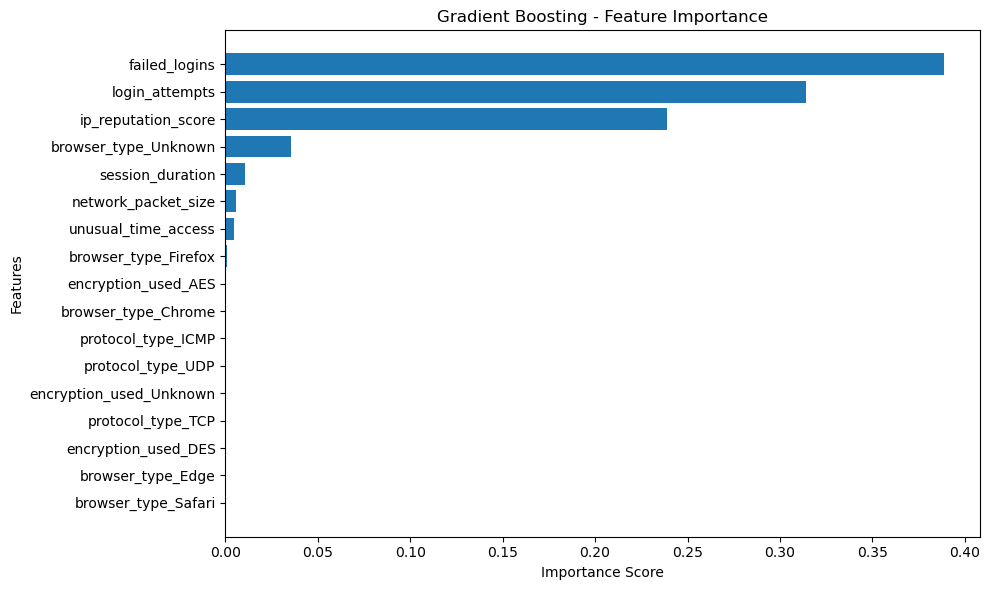

In [60]:
# Gradient Boosting - Feature Importance Graph

import pandas as pd
import matplotlib.pyplot as plt

feature_importance_gb = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_gb.feature_importances_
})

feature_importance_gb = feature_importance_gb.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_gb)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_gb["Feature"],
    feature_importance_gb["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Gradient Boosting - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [61]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

model_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)

print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.8862683438155137

Confusion Matrix:
[[1055    0]
 [ 217  636]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      1055
           1       1.00      0.75      0.85       853

    accuracy                           0.89      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.91      0.89      0.88      1908



In [62]:
#prediction threshold:-

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Attack probability predict karo
y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

# Threshold 0.3 set karo
y_pred_xgb_03 = (y_prob_xgb >= 0.3).astype(int)

print("Threshold: 0.3")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_03))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_03))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_03))

Threshold: 0.3
Accuracy: 0.8815513626834381

Confusion Matrix:
[[1040   15]
 [ 211  642]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1055
           1       0.98      0.75      0.85       853

    accuracy                           0.88      1908
   macro avg       0.90      0.87      0.88      1908
weighted avg       0.90      0.88      0.88      1908



In [63]:
#threshold = 0.2

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

y_pred_xgb_02 = (y_prob_xgb >= 0.2).astype(int)

print("Threshold: 0.2")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_02))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_02))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_02))

Threshold: 0.2
Accuracy: 0.8139412997903563

Confusion Matrix:
[[880 175]
 [180 673]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1055
           1       0.79      0.79      0.79       853

    accuracy                           0.81      1908
   macro avg       0.81      0.81      0.81      1908
weighted avg       0.81      0.81      0.81      1908



                    Feature  Importance
4             failed_logins    0.407181
1            login_attempts    0.253399
3       ip_reputation_score    0.108403
16     browser_type_Unknown    0.087374
5       unusual_time_access    0.020509
2          session_duration    0.013849
12      browser_type_Chrome    0.013686
9       encryption_used_AES    0.012241
0       network_packet_size    0.010793
13        browser_type_Edge    0.010589
10      encryption_used_DES    0.010483
14     browser_type_Firefox    0.010184
15      browser_type_Safari    0.009729
11  encryption_used_Unknown    0.008166
8         protocol_type_UDP    0.007985
6        protocol_type_ICMP    0.007760
7         protocol_type_TCP    0.007667


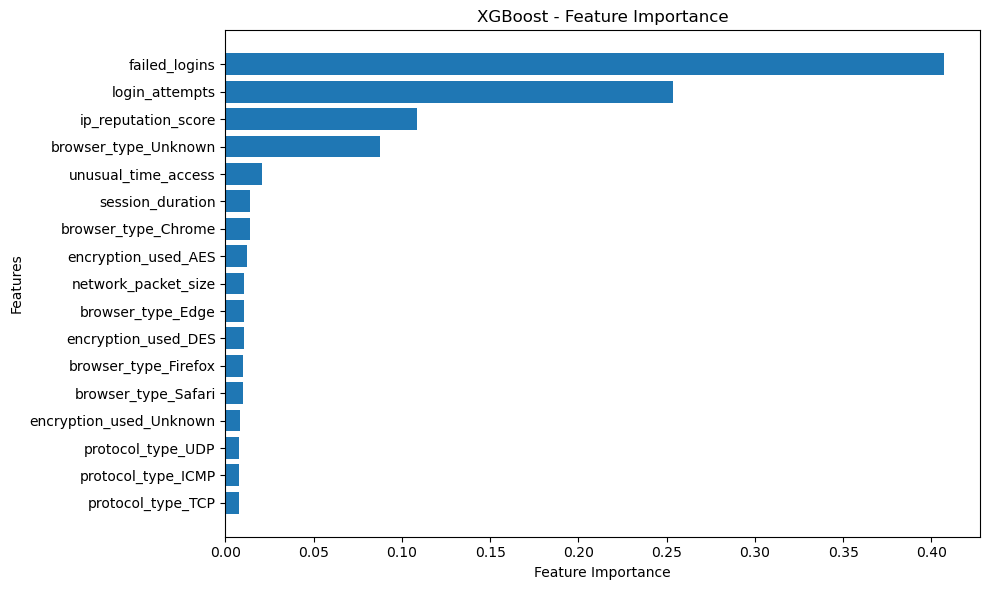

In [64]:
#graph for xg boost:-

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("XGBoost - Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [68]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model_xgb, "models/xgboost_model.pkl")
joblib.dump(list(X_train.columns), "models/model_features.pkl")

print("Model saved successfully!")
print("Filed saved:")
print("1. models/xgboost_model.pkl")
print("2. models/model_features.pkl")

Model saved successfully!
Filed saved:
1. models/xgboost_model.pkl
2. models/model_features.pkl


In [69]:
import joblib

loaded_model = joblib.load("models/xgboost_model.pkl")

sample_data = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_data)[0]
probability = loaded_model.predict_proba(sample_data)[0][1]

print("Prediction:", prediction)
print("Attack Probability:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Result: Potential Attack Detected!")
else:
    print("Result: Normal Session")

Prediction: 1
Attack Probability: 99.2 %
Result: Potential Attack Detected!
